# Main Pipeline

In [1]:
import os, re, glob, hashlib, time, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, stats
from scipy.ndimage import uniform_filter1d
from IPython.display import display
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

DATA_DIR   = "MI_DATA-20261119T122010Z-1-001/MI_DATA"
TRIAL_GLOB = os.path.join(DATA_DIR, "MI", "MI CSV", "cellula_MI_data_*.csv")
LABELS_CSV = os.path.join(DATA_DIR, "labels.csv")
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

cfg = {"fs": 250, "trial_seconds": 10, "channels": ["FZ", "C3", "CZ", "C4"],
       "bandpass_hz": [0.5, 40], "notch_hz": 50, "notch_q": 30,
       "artifact": {"edge_seconds": 1.0, "iqr_factor": 3, "flat_share_limit": 0.1},
       "epoch_seconds": [1.0, 9.0], "session_gap_seconds": 60, "random_seed": 42}
FS, CH, SEED = cfg["fs"], cfg["channels"], cfg["random_seed"]
N = FS * cfg["trial_seconds"]
C3, C4 = CH.index("C3"), CH.index("C4")
MU, BETA = (8, 12), (13, 30)
BANDS = {"mu 8–12": MU, "beta 13–30": BETA}
COL = {"LEFT": "tab:blue", "RIGHT": "tab:red"}
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def cohen_d(a, b):
    return (np.mean(b) - np.mean(a)) / np.sqrt((np.var(a, ddof=1) + np.var(b, ddof=1)) / 2)

print("Setup OK | FS =", FS, "Hz | channels:", CH)

Setup OK | FS = 250 Hz | channels: ['FZ', 'C3', 'CZ', 'C4']


## 1. Data and labels
### 1.1 Class balance

Trial files: 2160 | numbers 1..N with no gaps: True
Rows in labels.csv: 2400 | columns: ['label']
Labels with no file (not used): 240
       count  percent
label                
LEFT    1082    50.09
RIGHT   1078    49.91
Majority/minority ratio = 1.004 (close to 1.0 = balanced)


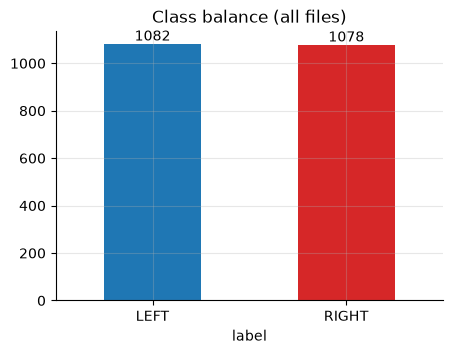

In [2]:
num = lambda p: int(re.search(r"(\d+)\.csv$", os.path.basename(p)).group(1))
files = sorted(glob.glob(TRIAL_GLOB), key=num)
labels_raw = pd.read_csv(LABELS_CSV)
all_labels = labels_raw["label"].astype(str).str.strip().str.upper().values

print("Trial files:", len(files), "| numbers 1..N with no gaps:", [num(f) for f in files] == list(range(1, len(files) + 1)))
print("Rows in labels.csv:", len(labels_raw), "| columns:", list(labels_raw.columns))
print("Labels with no file (not used):", len(all_labels) - len(files))

trials = pd.DataFrame({"trial_id": range(len(files)), "filename": [os.path.basename(f) for f in files],
                       "path": files, "label": all_labels[:len(files)]})
counts = trials["label"].value_counts()
print(pd.DataFrame({"count": counts, "percent": (100 * counts / counts.sum()).round(2)}).to_string())
print(f"Majority/minority ratio = {counts.max() / counts.min():.3f} (close to 1.0 = balanced)")

ax = counts.plot(kind="bar", color=[COL[c] for c in counts.index], rot=0, title="Class balance (all files)", figsize=(5, 3.5))
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.show()

### 1.2 Channels, length, sampling rate

Read 2160 files in 70 s
Channel sets:   {'FZ,C3,CZ,C4': 2160}
Rows per file:  {2500: 2160}
Files with NaN: 0
Duration (s):   {'min': 8.734, '50%': 9.985, 'max': 11.48}
Rate = samples / duration (Hz): {'min': 217.69, '50%': 250.27, 'max': 286.13}
File 1: rate from MEDIAN time step = 416 Hz | from MEAN time step = 250.0 Hz
X_raw: (2160, 4, 2500) (trials, channels, samples)

Trial 1 per-channel statistics (raw values):


,count,mean,std,min,25%,50%,75%,max
FZ,2500.0,324770.4,182.4,324489.8,324593.3,324757.0,324942.4,325086.8
C3,2500.0,320966.2,181.4,320697.8,320797.0,320947.9,321146.3,321280.7
CZ,2500.0,334986.3,281.4,334553.2,334707.2,334967.1,335273.0,335460.7
C4,2500.0,320801.7,428.5,320128.7,320362.1,320798.9,321228.1,321480.1


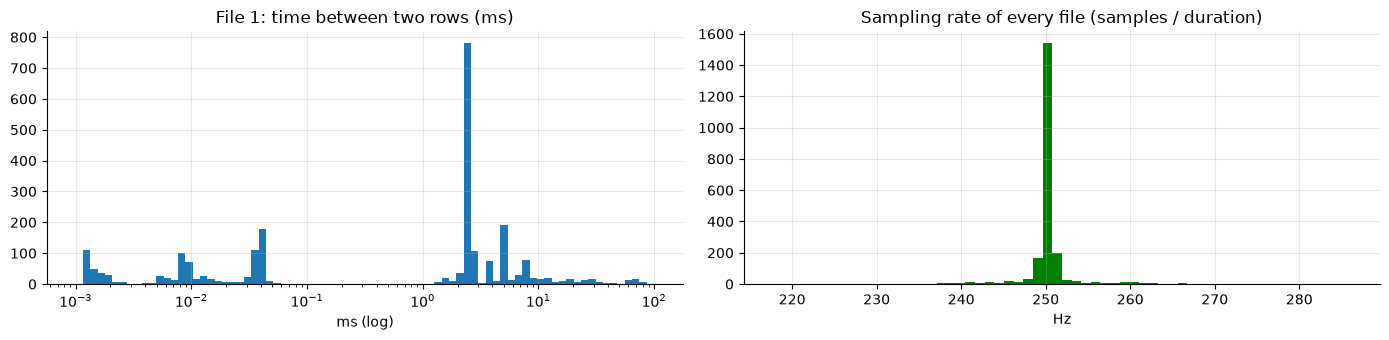

In [3]:
rows, arrays = [], []
t0 = time.time()
for p in trials["path"]:
    df = pd.read_csv(p)
    sig = df[CH].to_numpy(dtype=float)
    rows.append({"channels": ",".join(c for c in df.columns if c != "Time"), "rows": len(df),
                 "n_nan": int(df[CH].isna().sum().sum()), "t_start": df["Time"].iloc[0], "t_end": df["Time"].iloc[-1],
                 "hash": hashlib.md5(np.ascontiguousarray(sig).tobytes()).hexdigest()})
    arrays.append(sig)
trials = pd.concat([trials, pd.DataFrame(rows)], axis=1)
trials["duration_s"] = trials["t_end"] - trials["t_start"]
trials["rate_hz"] = (trials["rows"] - 1) / trials["duration_s"]
print(f"Read {len(trials)} files in {time.time() - t0:.0f} s")
print("Channel sets:  ", trials["channels"].value_counts().to_dict())
print("Rows per file: ", trials["rows"].value_counts().to_dict())
print("Files with NaN:", int((trials["n_nan"] > 0).sum()))
print("Duration (s):  ", trials["duration_s"].describe()[["min", "50%", "max"]].round(3).to_dict())
print("Rate = samples / duration (Hz):", trials["rate_hz"].describe()[["min", "50%", "max"]].round(2).to_dict())

gaps = np.diff(pd.read_csv(files[0])["Time"].values)
print(f"File 1: rate from MEDIAN time step = {1 / np.median(gaps):.0f} Hz | from MEAN time step = {1 / gaps.mean():.1f} Hz")

assert trials["channels"].nunique() == 1 and trials["rows"].nunique() == 1, "files differ in channels or length"
X_raw = np.stack([a[:N].T for a in arrays]); del arrays
y_all = trials["label"].values
t = np.arange(N) / FS
print("X_raw:", X_raw.shape, "(trials, channels, samples)")

print("\nTrial 1 per-channel statistics (raw values):")
display(pd.DataFrame(X_raw[0].T, columns=CH).describe().T.round(1))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
ax[0].hist(gaps * 1000, bins=np.logspace(-3, 2, 80)); ax[0].set_xscale("log")
ax[0].set_title("File 1: time between two rows (ms)"); ax[0].set_xlabel("ms (log)")
ax[1].hist(trials["rate_hz"], bins=60, color="green")
ax[1].set_title("Sampling rate of every file (samples / duration)"); ax[1].set_xlabel("Hz")
plt.tight_layout(); plt.show()

## 2. Artifact rejection

Limits: {'peak_to_peak': 8385.04, 'std': 809.16, 'flat_share': 0.1}
Removed: 269 of 2160 (12.5%) -> saved outputs/removed_trials.csv
Removal rate per class: {'LEFT': 0.124, 'RIGHT': 0.125}
Is rejection linked to the class? chi-square p = 0.97


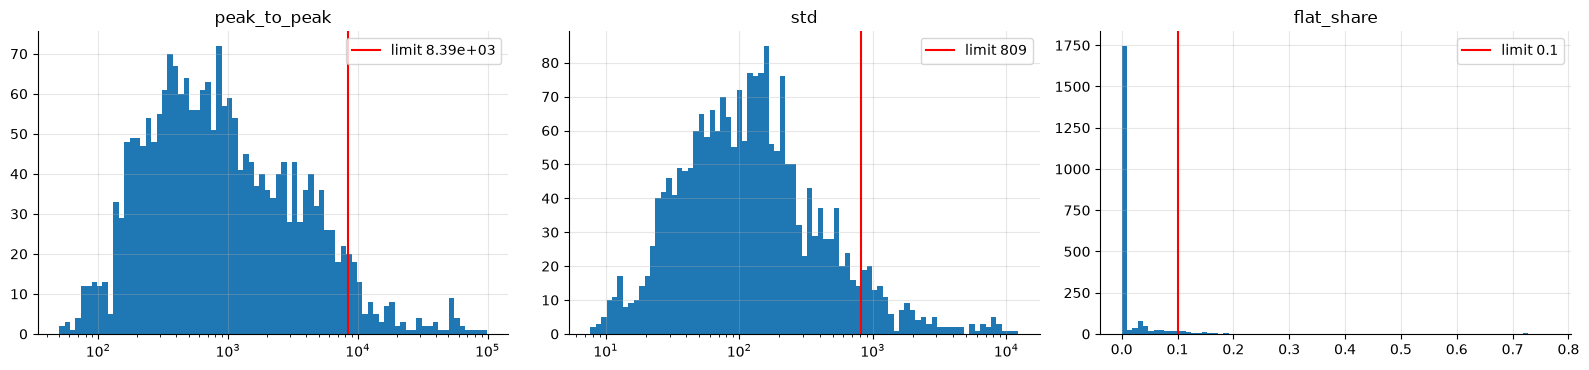

Kept: 1891 | {'LEFT': 948, 'RIGHT': 943} | epochs: (1891, 4, 2000)


In [4]:
sos_bp = signal.butter(4, cfg["bandpass_hz"], btype="bandpass", fs=FS, output="sos")
b_notch, a_notch = signal.iirnotch(cfg["notch_hz"], cfg["notch_q"], fs=FS)
X_filt = signal.sosfiltfilt(sos_bp, X_raw - X_raw.mean(-1, keepdims=True), axis=-1)
X_filt = signal.filtfilt(b_notch, a_notch, X_filt, axis=-1)

e = int(cfg["artifact"]["edge_seconds"] * FS)
core = X_filt[..., e:-e]
m = {"peak_to_peak": np.ptp(core, axis=-1).max(1),
     "std": core.std(-1).max(1),
     "flat_share": (np.diff(X_raw, axis=-1) == 0).mean(-1).max(1)}
del core

k_iqr = cfg["artifact"]["iqr_factor"]
limits = {name: float(np.percentile(m[name], 75) + k_iqr * stats.iqr(m[name])) for name in ("peak_to_peak", "std")}
limits["flat_share"] = cfg["artifact"]["flat_share_limit"]
flags = pd.DataFrame({k: m[k] > limits[k] for k in limits})
bad = flags.any(axis=1).values
names = {"peak_to_peak": "peaks", "std": "too big", "flat_share": "flat"}
reason = flags.apply(lambda r: " + ".join(names[k] for k in limits if r[k]), axis=1)
removed = trials.loc[bad, ["filename", "label"]].copy()
removed["reason"] = reason[bad].values
for k in limits:
    removed[k] = np.round(m[k][bad], 3)
removed.to_csv(f"{OUT}/removed_trials.csv", index=False)

print("Limits:", {k: round(v, 2) for k, v in limits.items()})
print(f"Removed: {bad.sum()} of {len(bad)} ({bad.mean():.1%}) -> saved {OUT}/removed_trials.csv")
print("Removal rate per class:", pd.Series(bad).groupby(y_all).mean().round(3).to_dict())
print(f"Is rejection linked to the class? chi-square p = {stats.chi2_contingency(pd.crosstab(y_all, bad)).pvalue:.2f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a_, k in zip(ax, limits):
    v = m[k]
    bins = np.logspace(np.log10(v[v > 0].min()), np.log10(v.max()), 80) if k != "flat_share" else 80
    a_.hist(v, bins=bins); a_.axvline(limits[k], color="red", label=f"limit {limits[k]:.3g}")
    if k != "flat_share": a_.set_xscale("log")
    a_.set_title(k); a_.legend()
plt.tight_layout(); plt.show()

keep = ~bad
X_raw_k, X_filt_k = X_raw[keep], X_filt[keep]
trials_k = trials[keep].reset_index(drop=True)
y = y_all[keep]
X_car_k = X_filt_k - X_filt_k.mean(axis=1, keepdims=True)
s0, s1 = (int(s * FS) for s in cfg["epoch_seconds"])
X_ep_nocar = X_filt_k[..., s0:s1] - X_filt_k[..., s0:s1].mean(-1, keepdims=True)
X_ep_car = X_car_k[..., s0:s1] - X_car_k[..., s0:s1].mean(-1, keepdims=True)
print("Kept:", len(y), "|", pd.Series(y).value_counts().to_dict(), "| epochs:", X_ep_nocar.shape)

## 3. Must-do checks

,Result
Check,
Class balance (all files),LEFT 1082 / RIGHT 1078 (RIGHT share 49.9%)
Class balance (after rejection),LEFT 948 / RIGHT 943 (RIGHT share 49.9%)
Sampling rate,217.69–286.13 Hz per file -> 250 Hz
Trial length,[2500] rows = 10 s in every file
Channel names,"['FZ,C3,CZ,C4'] in every file"
Missing values / NaN,0 files
Flat channels (>10% repeated values),"FZ: 124, C3: 124, CZ: 124, C4: 124 trials"
Extreme outliers (peaks / too big),118 / 159 trials
Rejected by artifact rules,"269 of 2160 = 12.5% (LEFT 134, RIGHT 135)"


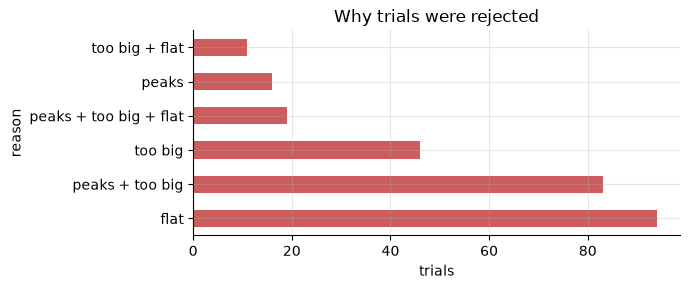

In [5]:
before, after = pd.Series(y_all).value_counts(), pd.Series(y).value_counts()
flat_ch = (np.diff(X_raw, axis=-1) == 0).mean(-1)
flat_per_ch = pd.Series((flat_ch > cfg["artifact"]["flat_share_limit"]).sum(0), index=CH)
checks = pd.DataFrame([
    ["Class balance (all files)", f"LEFT {before['LEFT']} / RIGHT {before['RIGHT']} (RIGHT share {before['RIGHT'] / before.sum():.1%})"],
    ["Class balance (after rejection)", f"LEFT {after['LEFT']} / RIGHT {after['RIGHT']} (RIGHT share {after['RIGHT'] / after.sum():.1%})"],
    ["Sampling rate", f"{trials['rate_hz'].min():.2f}–{trials['rate_hz'].max():.2f} Hz per file -> {FS} Hz"],
    ["Trial length", f"{trials['rows'].unique().tolist()} rows = {N / FS:.0f} s in every file"],
    ["Channel names", f"{trials['channels'].unique().tolist()} in every file"],
    ["Missing values / NaN", f"{int((trials['n_nan'] > 0).sum())} files"],
    ["Flat channels (>10% repeated values)", ", ".join(f"{c}: {n}" for c, n in flat_per_ch.items()) + " trials"],
    ["Extreme outliers (peaks / too big)", f"{int(flags['peak_to_peak'].sum())} / {int(flags['std'].sum())} trials"],
    ["Rejected by artifact rules", f"{bad.sum()} of {len(bad)} = {bad.mean():.1%} (LEFT {int(removed['label'].eq('LEFT').sum())}, RIGHT {int(removed['label'].eq('RIGHT').sum())})"],
], columns=["Check", "Result"])
pd.set_option("display.max_colwidth", None)
display(checks.set_index("Check"))

ax = removed["reason"].value_counts().plot(kind="barh", color="indianred", figsize=(7, 3))
ax.set_title("Why trials were rejected"); ax.set_xlabel("trials")
plt.tight_layout(); plt.show()

## 4. Time-domain signals

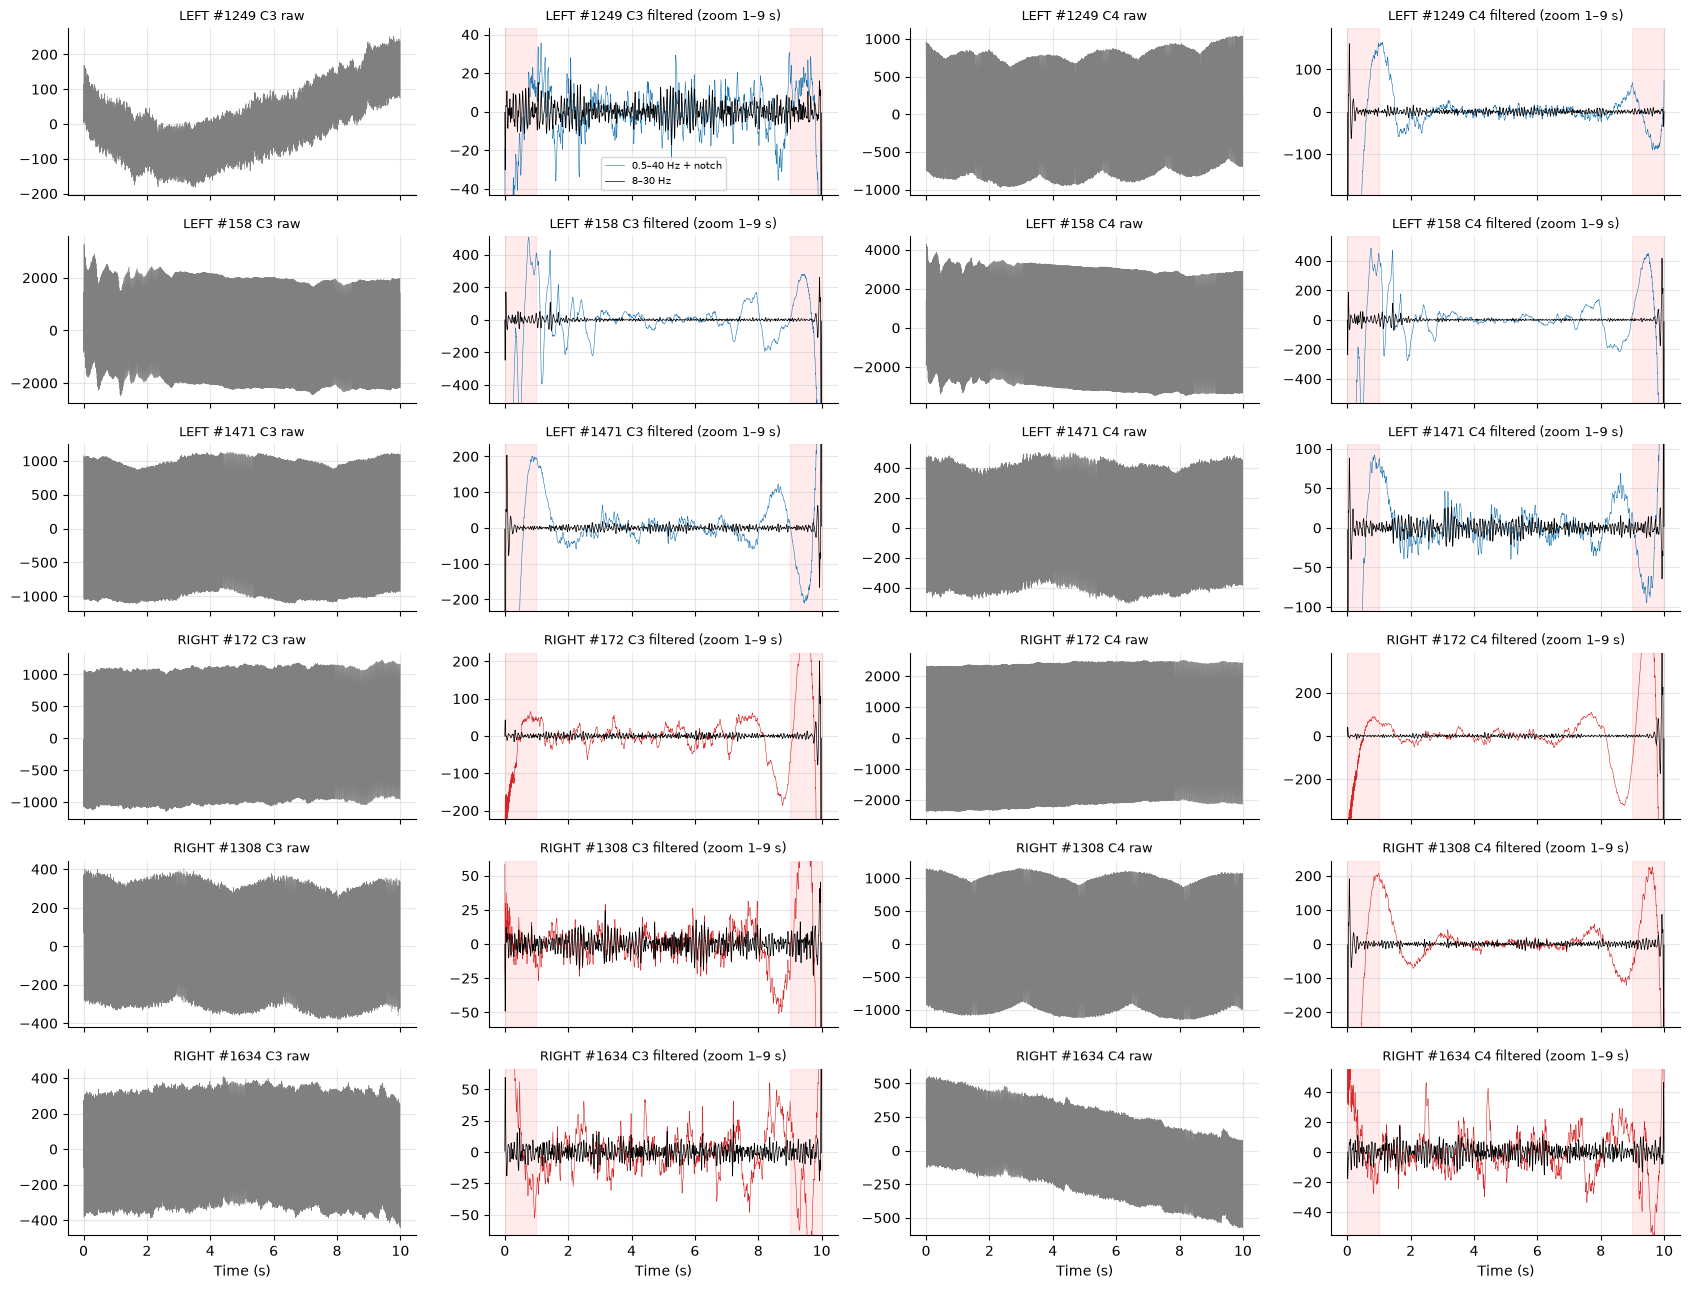

Median peak-to-peak on C3/C4: raw 1,586 | filtered (1–9 s) 197 | ratio x8


In [6]:
sos830 = signal.butter(4, [8, 30], btype="bandpass", fs=FS, output="sos")
rng = np.random.default_rng(SEED)
pick = [(int(i), lab) for lab in ("LEFT", "RIGHT") for i in rng.choice(np.where(y == lab)[0], 3, replace=False)]
fig, ax = plt.subplots(6, 4, figsize=(17, 13), sharex=True)
for r, (i, lab) in enumerate(pick):
    for c, ch in enumerate([C3, C4]):
        ax[r, 2 * c].plot(t, X_raw_k[i, ch] - X_raw_k[i, ch].mean(), lw=0.4, color="grey")
        ax[r, 2 * c].set_title(f"{lab} #{i} {CH[ch]} raw", fontsize=9)
        a_ = ax[r, 2 * c + 1]
        a_.plot(t, X_filt_k[i, ch], lw=0.4, color=COL[lab], label="0.5–40 Hz + notch")
        a_.plot(t, signal.sosfiltfilt(sos830, X_filt_k[i, ch]), lw=0.5, color="black", label="8–30 Hz")
        lim_ = 1.2 * np.abs(X_filt_k[i, ch, FS:-FS]).max()
        a_.set_ylim(-lim_, lim_); a_.axvspan(0, 1, color="red", alpha=0.08); a_.axvspan(9, 10, color="red", alpha=0.08)
        a_.set_title(f"{lab} #{i} {CH[ch]} filtered (zoom 1–9 s)", fontsize=9)
ax[0, 1].legend(fontsize=7)
for a_ in ax[-1]: a_.set_xlabel("Time (s)")
plt.tight_layout(); plt.show()

amp_raw = np.median([np.ptp(X_raw_k[i, [C3, C4]], axis=-1).mean() for i, _ in pick])
amp_f = np.median([np.ptp(X_filt_k[i, [C3, C4], FS:-FS], axis=-1).mean() for i, _ in pick])
print(f"Median peak-to-peak on C3/C4: raw {amp_raw:,.0f} | filtered (1–9 s) {amp_f:,.0f} | ratio x{amp_raw / amp_f:.0f}")

## 5. Spectra
### 5.1 PSD: LEFT vs RIGHT

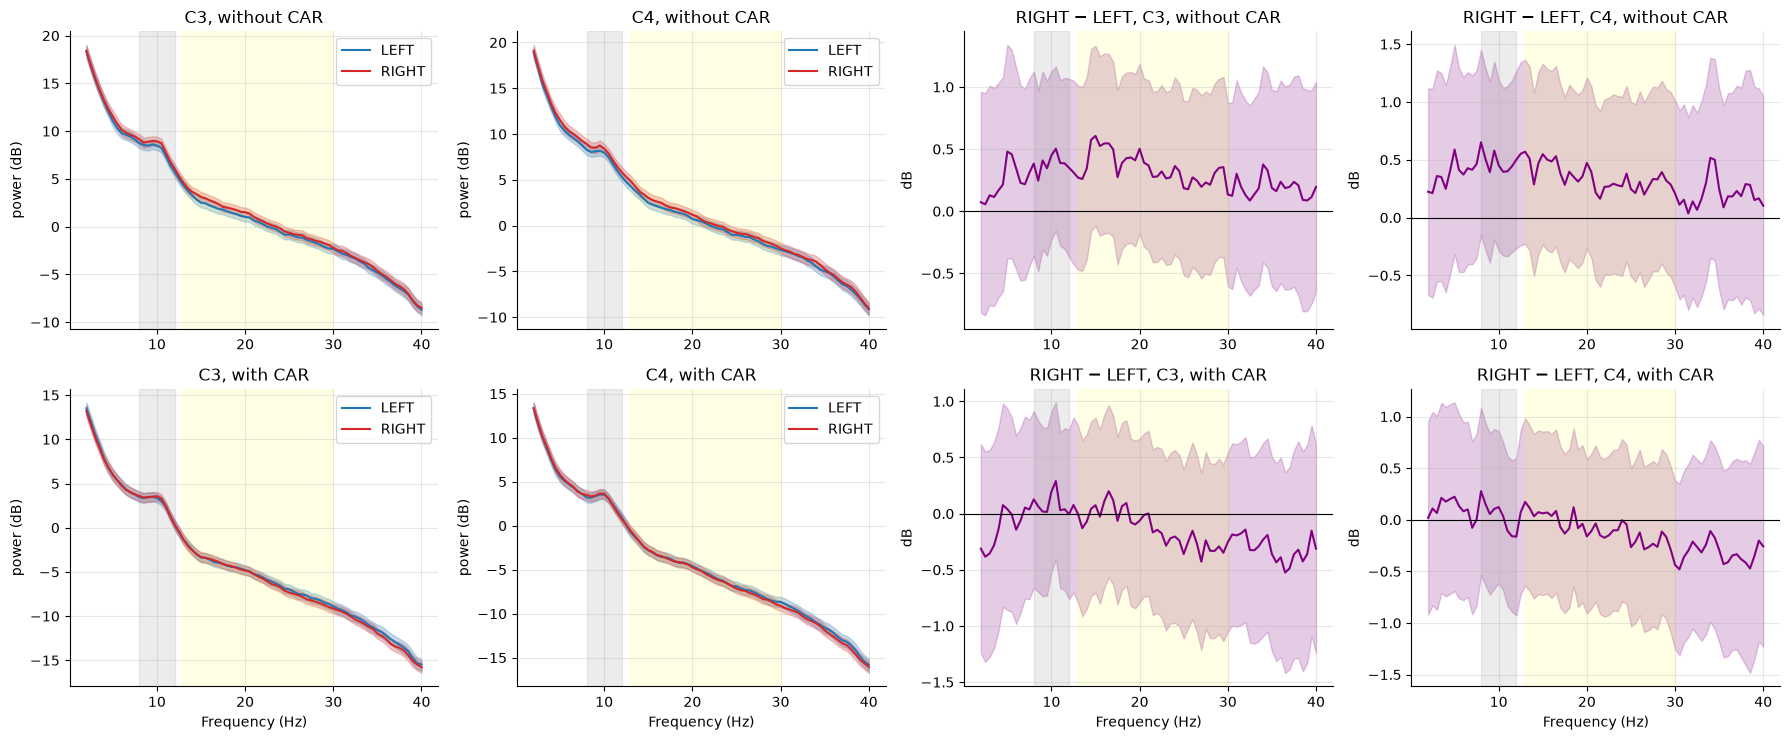

,version,channel,band,RIGHT − LEFT (dB),t-test p,expected sign,matches expected
0,without CAR,C3,mu 8–12,0.384,0.255,−,False
1,without CAR,C3,beta 13–30,0.347,0.315,−,False
2,without CAR,C4,mu 8–12,0.481,0.195,+,True
3,without CAR,C4,beta 13–30,0.346,0.359,+,True
4,with CAR,C3,mu 8–12,0.086,0.807,−,False
5,with CAR,C3,beta 13–30,-0.129,0.730,−,True
6,with CAR,C4,mu 8–12,0.036,0.923,+,True
7,with CAR,C4,beta 13–30,-0.095,0.804,+,False


In [7]:
f, P_nocar = signal.welch(X_ep_nocar, fs=FS, nperseg=2 * FS, axis=-1)
_, P_car = signal.welch(X_ep_car, fs=FS, nperseg=2 * FS, axis=-1)
PS = {"without CAR": P_nocar, "with CAR": P_car}
fb = (f >= 2) & (f <= 40)
fig, ax = plt.subplots(2, 4, figsize=(18, 7.5))
rows = []
for r, (vname, P) in enumerate(PS.items()):
    L = 10 * np.log10(P)
    for c, ch in enumerate([C3, C4]):
        a_ = ax[r, c]
        for lab in ("LEFT", "RIGHT"):
            v = L[y == lab, ch][:, fb]; mu_, se = v.mean(0), v.std(0) / np.sqrt(len(v))
            a_.plot(f[fb], mu_, color=COL[lab], label=lab); a_.fill_between(f[fb], mu_ - 1.96 * se, mu_ + 1.96 * se, color=COL[lab], alpha=0.25)
        a_.axvspan(*MU, color="grey", alpha=0.15); a_.axvspan(*BETA, color="yellow", alpha=0.1)
        a_.set_title(f"{CH[ch]}, {vname}"); a_.set_ylabel("power (dB)"); a_.legend()
        d_ = ax[r, c + 2]
        lv, rv = L[y == "LEFT", ch][:, fb], L[y == "RIGHT", ch][:, fb]
        diff = rv.mean(0) - lv.mean(0); se = np.sqrt(lv.var(0) / len(lv) + rv.var(0) / len(rv))
        d_.plot(f[fb], diff, color="purple"); d_.fill_between(f[fb], diff - 1.96 * se, diff + 1.96 * se, color="purple", alpha=0.2)
        d_.axhline(0, color="black", lw=0.8); d_.axvspan(*MU, color="grey", alpha=0.15); d_.axvspan(*BETA, color="yellow", alpha=0.1)
        d_.set_title(f"RIGHT − LEFT, {CH[ch]}, {vname}"); d_.set_ylabel("dB")
        for bname, (lo, hi) in BANDS.items():
            sel = (f >= lo) & (f <= hi)
            lb, rb = L[y == "LEFT", ch][:, sel].mean(1), L[y == "RIGHT", ch][:, sel].mean(1)
            rows.append({"version": vname, "channel": CH[ch], "band": bname, "RIGHT − LEFT (dB)": rb.mean() - lb.mean(),
                         "t-test p": stats.ttest_ind(rb, lb).pvalue, "expected sign": "−" if ch == C3 else "+"})
for a_ in ax[-1]: a_.set_xlabel("Frequency (Hz)")
plt.tight_layout(); plt.show()
psd_tab = pd.DataFrame(rows)
psd_tab["matches expected"] = np.where(psd_tab["expected sign"] == "−", psd_tab["RIGHT − LEFT (dB)"] < 0, psd_tab["RIGHT − LEFT (dB)"] > 0)
psd_tab.round(3)

### 5.2 Log-log PSD

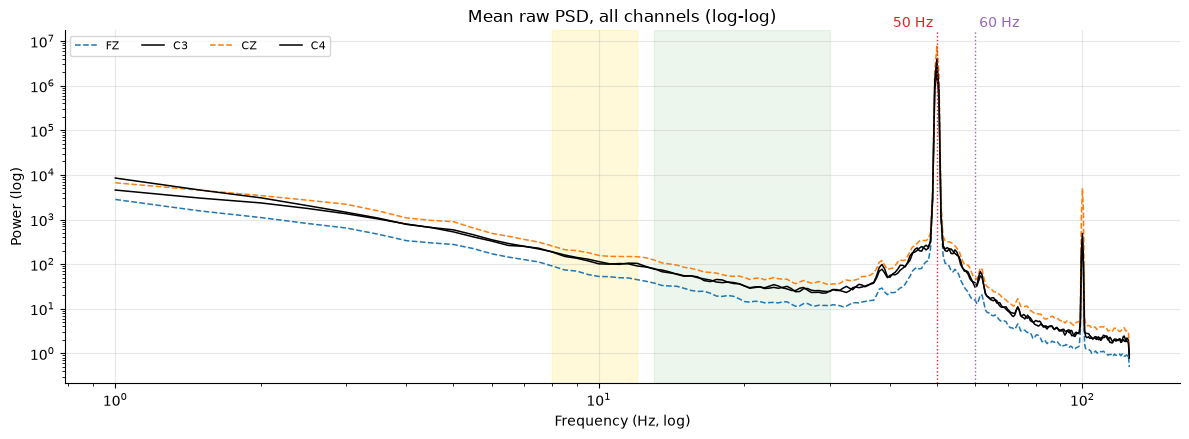

,channel,1/f slope (1-40 Hz),50 Hz vs neighbours (x),60 Hz vs neighbours (x)
0,FZ,-1.51,48630.5,0.41
1,C3,-1.46,11443.7,0.38
2,CZ,-1.45,31372.3,0.39
3,C4,-1.53,22888.4,0.34


In [8]:
f_raw, P_raw = signal.welch(X_raw_k, fs=FS, nperseg=2 * FS, axis=-1)
mean_psd = P_raw.mean(axis=0)
m_plot = f_raw >= 1
fig, ax = plt.subplots(figsize=(12, 4.5))
for k, ch in enumerate(CH):
    ax.loglog(f_raw[m_plot], mean_psd[k, m_plot], lw=1.1, label=ch,
              color="black" if k in (C3, C4) else None, ls="-" if k in (C3, C4) else "--")
for hz, col, side in [(50, "tab:red", "right"), (60, "tab:purple", "left")]:
    ax.axvline(hz, color=col, ls=":", lw=1); ax.text(hz, ax.get_ylim()[1], f" {hz} Hz ", color=col, ha=side, va="bottom")
ax.axvspan(*MU, color="gold", alpha=0.15); ax.axvspan(*BETA, color="green", alpha=0.07)
ax.set_xlabel("Frequency (Hz, log)"); ax.set_ylabel("Power (log)"); ax.set_title("Mean raw PSD, all channels (log-log)")
ax.legend(ncol=4, fontsize=8); plt.tight_layout(); plt.show()

at = lambda p, hz: p[np.argmin(np.abs(f_raw - hz))]
m_fit = (f_raw >= 1) & (f_raw <= 40) & ~((f_raw >= 7) & (f_raw <= 14)) & ~((f_raw >= 17) & (f_raw <= 23))
pd.DataFrame([{"channel": ch,
               "1/f slope (1-40 Hz)": round(np.polyfit(np.log10(f_raw[m_fit]), np.log10(mean_psd[k, m_fit]), 1)[0], 2),
               "50 Hz vs neighbours (x)": round(at(mean_psd[k], 50) / np.mean([at(mean_psd[k], 45), at(mean_psd[k], 55)]), 1),
               "60 Hz vs neighbours (x)": round(at(mean_psd[k], 60) / np.mean([at(mean_psd[k], 55), at(mean_psd[k], 65)]), 2)}
              for k, ch in enumerate(CH)])

### 5.3 Peak mu frequency

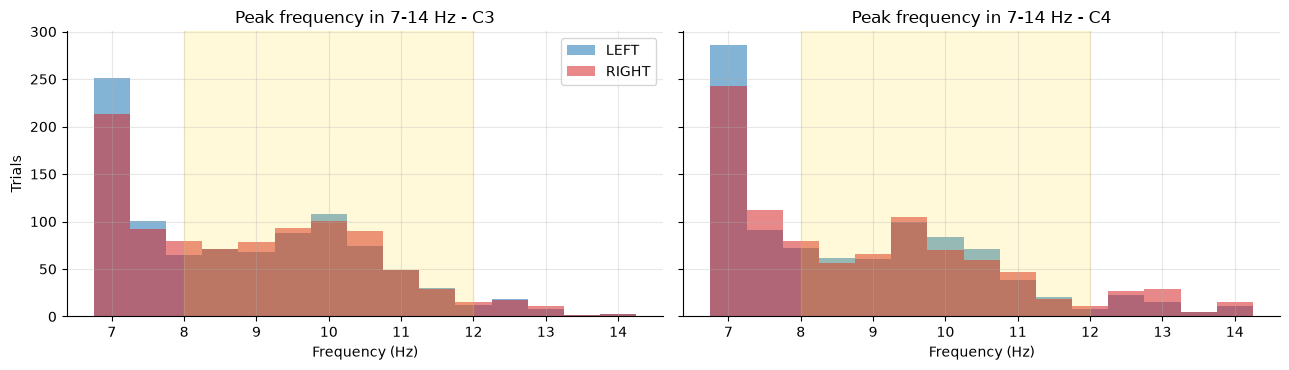

,channel,most common peak (Hz),share at the 7 Hz edge (%),peak std (Hz)
0,C3,7.0,24.5,1.63
1,C4,7.0,28.0,1.80


In [9]:
PEAK_RANGE = (7, 14)
m_peak = (f_raw >= PEAK_RANGE[0]) & (f_raw <= PEAK_RANGE[1])
peak_f = {ch: f_raw[m_peak][P_raw[:, ch][:, m_peak].argmax(axis=1)] for ch in (C3, C4)}
bins = np.arange(PEAK_RANGE[0] - 0.25, PEAK_RANGE[1] + 0.5, 0.5)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, ch in zip(axes, (C3, C4)):
    for lab in ("LEFT", "RIGHT"):
        ax.hist(peak_f[ch][y == lab], bins=bins, alpha=0.55, color=COL[lab], label=lab)
    ax.axvspan(*MU, color="gold", alpha=0.15)
    ax.set_title(f"Peak frequency in {PEAK_RANGE[0]}-{PEAK_RANGE[1]} Hz - {CH[ch]}"); ax.set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Trials"); axes[0].legend(); plt.tight_layout(); plt.show()

rows = []
for ch in (C3, C4):
    vals, cnt = np.unique(peak_f[ch], return_counts=True)
    rows.append({"channel": CH[ch], "most common peak (Hz)": vals[cnt.argmax()],
                 "share at the 7 Hz edge (%)": round(100 * (peak_f[ch] == PEAK_RANGE[0]).mean(), 1),
                 "peak std (Hz)": round(float(peak_f[ch].std()), 2)})
pd.DataFrame(rows)

## 6. ERD
### 6.1 Mu power over time

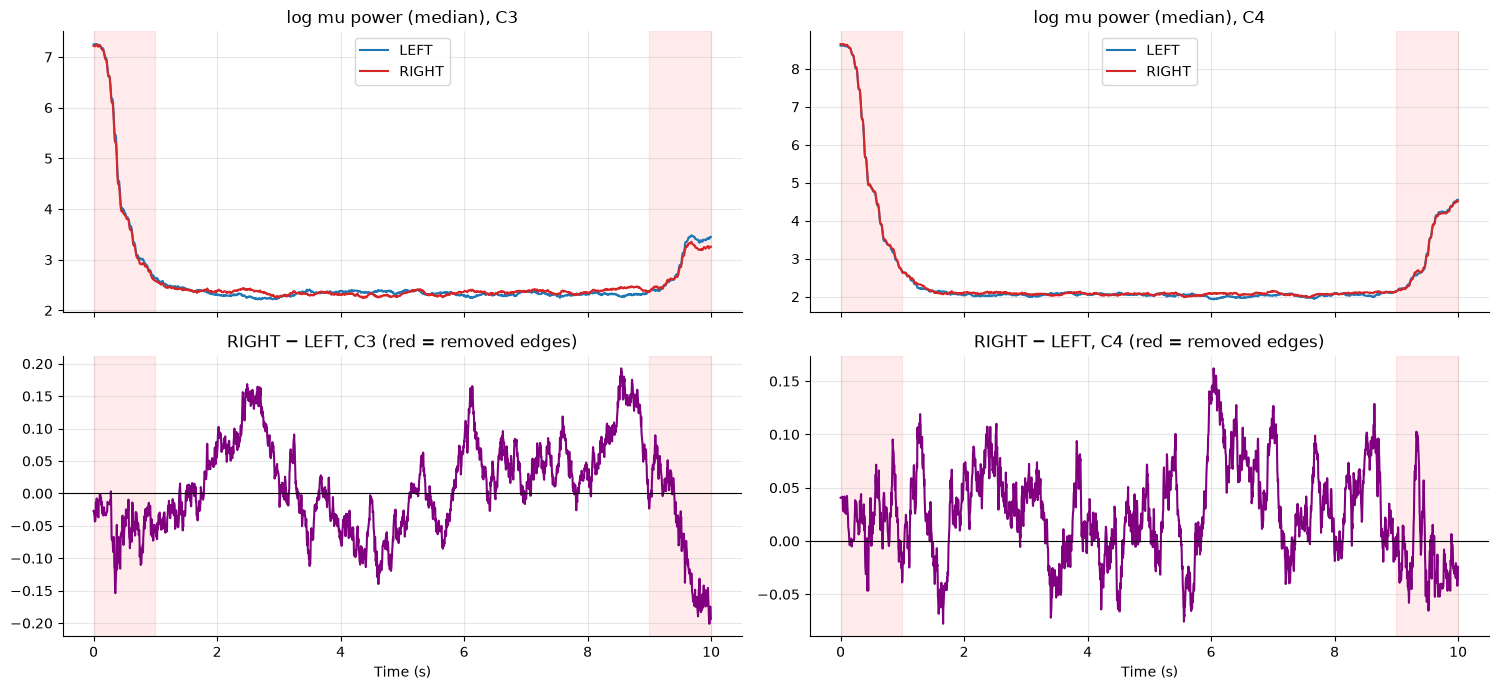

   0–0.5  s: log-mu +4.64 vs the 2–8 s level
 0.5–1    s: log-mu +1.19 vs the 2–8 s level
   1–2    s: log-mu +0.13 vs the 2–8 s level
   8–9    s: log-mu +0.03 vs the 2–8 s level
   9–9.5  s: log-mu +0.30 vs the 2–8 s level
 9.5–10   s: log-mu +1.52 vs the 2–8 s level


In [10]:
mu_env = signal.sosfiltfilt(signal.butter(4, MU, btype="bandpass", fs=FS, output="sos"), X_filt_k[:, [C3, C4]], axis=-1) ** 2
mu_env = uniform_filter1d(mu_env, size=int(0.5 * FS), axis=-1)
log_mu = np.log(mu_env + 1e-12); del mu_env
fig, ax = plt.subplots(2, 2, figsize=(15, 7), sharex=True)
for k, name in enumerate(["C3", "C4"]):
    med_ = {lab: np.median(log_mu[y == lab, k], axis=0) for lab in ("LEFT", "RIGHT")}
    for lab in med_:
        ax[0, k].plot(t, med_[lab], color=COL[lab], label=lab)
    ax[1, k].plot(t, med_["RIGHT"] - med_["LEFT"], color="purple"); ax[1, k].axhline(0, color="black", lw=0.8)
    for a_ in ax[:, k]:
        a_.axvspan(0, cfg["epoch_seconds"][0], color="red", alpha=0.08); a_.axvspan(cfg["epoch_seconds"][1], 10, color="red", alpha=0.08)
    ax[0, k].set_title(f"log mu power (median), {name}"); ax[0, k].legend()
    ax[1, k].set_title(f"RIGHT − LEFT, {name} (red = removed edges)"); ax[1, k].set_xlabel("Time (s)")
plt.tight_layout(); plt.show()

whole = np.median(log_mu, axis=(0, 1)); mid = whole[(t > 2) & (t < 8)].mean()
for lo, hi in [(0, 0.5), (0.5, 1), (1, 2), (8, 9), (9, 9.5), (9.5, 10)]:
    print(f"{lo:>4}–{hi:<4} s: log-mu {whole[(t >= lo) & (t < hi)].mean() - mid:+.2f} vs the 2–8 s level")

### 6.2 Lateralization index

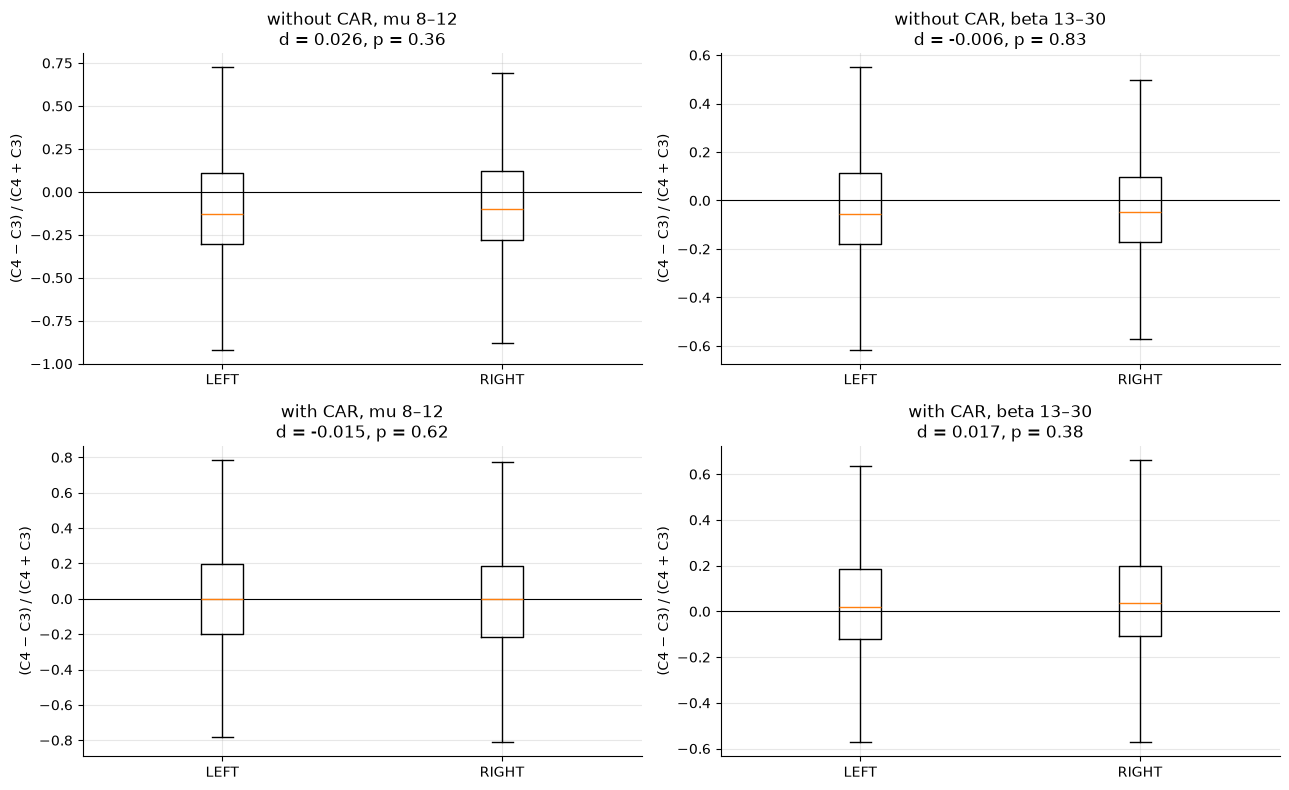

,window,version,band,median LI LEFT,median LI RIGHT,Cohen d (RIGHT−LEFT),Mann-Whitney p
0,1–9 s,without CAR,mu 8–12,-0.131,-0.101,0.026,0.356
1,1–9 s,without CAR,beta 13–30,-0.058,-0.048,-0.006,0.825
2,1–9 s,with CAR,mu 8–12,-0.000,-0.002,-0.015,0.620
3,1–9 s,with CAR,beta 13–30,0.018,0.035,0.017,0.383
4,4–9 s,without CAR,mu 8–12,-0.129,-0.130,-0.018,0.775
5,4–9 s,without CAR,beta 13–30,-0.071,-0.061,-0.026,0.876


In [11]:
s4 = int((4 - cfg["epoch_seconds"][0]) * FS)
f_l, P_late = signal.welch(X_ep_nocar[:, :, s4:], fs=FS, nperseg=2 * FS, axis=-1)
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
rows = []
for r, (vname, P) in enumerate(PS.items()):
    for c, (bname, (lo, hi)) in enumerate(BANDS.items()):
        bpw = P[..., (f >= lo) & (f <= hi)].mean(-1)
        li = (bpw[:, C4] - bpw[:, C3]) / (bpw[:, C4] + bpw[:, C3])
        l_, r_ = li[y == "LEFT"], li[y == "RIGHT"]
        d, p = cohen_d(l_, r_), stats.mannwhitneyu(l_, r_).pvalue
        rows.append({"window": "1–9 s", "version": vname, "band": bname, "median LI LEFT": np.median(l_),
                     "median LI RIGHT": np.median(r_), "Cohen d (RIGHT−LEFT)": d, "Mann-Whitney p": p})
        ax[r, c].boxplot([l_, r_], tick_labels=["LEFT", "RIGHT"], showfliers=False); ax[r, c].axhline(0, color="black", lw=0.8)
        ax[r, c].set_title(f"{vname}, {bname}\nd = {d:.3f}, p = {p:.2f}"); ax[r, c].set_ylabel("(C4 − C3) / (C4 + C3)")
plt.tight_layout(); plt.show()
for bname, (lo, hi) in BANDS.items():
    bpw = P_late[..., (f_l >= lo) & (f_l <= hi)].mean(-1)
    li = (bpw[:, C4] - bpw[:, C3]) / (bpw[:, C4] + bpw[:, C3])
    l_, r_ = li[y == "LEFT"], li[y == "RIGHT"]
    rows.append({"window": "4–9 s", "version": "without CAR", "band": bname, "median LI LEFT": np.median(l_),
                 "median LI RIGHT": np.median(r_), "Cohen d (RIGHT−LEFT)": cohen_d(l_, r_), "Mann-Whitney p": stats.mannwhitneyu(l_, r_).pvalue})
erd_tab = pd.DataFrame(rows); erd_tab.round(3)

### 6.3 Band power per channel

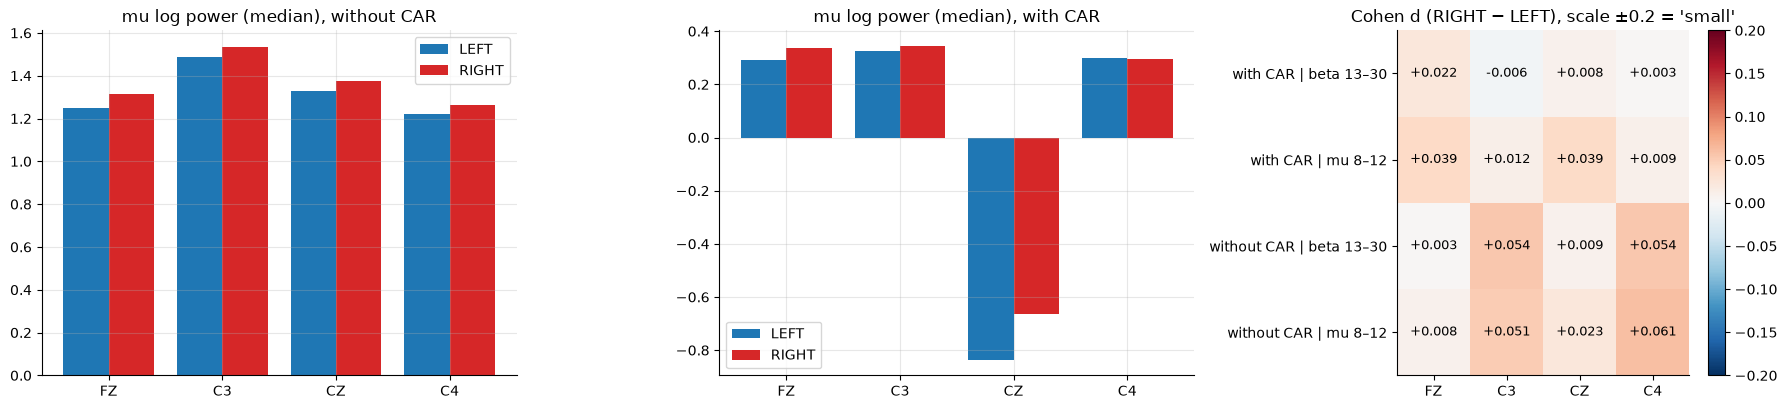

channel                    FZ     C3     CZ     C4
version     band                                  
with CAR    beta 13–30  0.022 -0.006  0.008  0.003
            mu 8–12     0.039  0.012  0.039  0.009
without CAR beta 13–30  0.003  0.054  0.009  0.054
            mu 8–12     0.008  0.051  0.023  0.061

In [12]:
rows = []
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2), gridspec_kw={"width_ratios": [1.3, 1.3, 1]})
for k, (vname, P) in enumerate(PS.items()):
    for bname, (lo, hi) in BANDS.items():
        lp = np.log(P[..., (f >= lo) & (f <= hi)].mean(-1))
        for ch in range(len(CH)):
            rows.append({"version": vname, "band": bname, "channel": CH[ch], "d": cohen_d(lp[y == "LEFT", ch], lp[y == "RIGHT", ch])})
    lp = np.log(P[..., (f >= MU[0]) & (f <= MU[1])].mean(-1)); x_ = np.arange(len(CH))
    ax[k].bar(x_ - 0.2, np.median(lp[y == "LEFT"], 0), 0.4, color=COL["LEFT"], label="LEFT")
    ax[k].bar(x_ + 0.2, np.median(lp[y == "RIGHT"], 0), 0.4, color=COL["RIGHT"], label="RIGHT")
    ax[k].set_xticks(x_, CH); ax[k].set_title(f"mu log power (median), {vname}"); ax[k].legend()
bp_tab = pd.DataFrame(rows)
heat = bp_tab.pivot_table(index=["version", "band"], columns="channel", values="d")[CH]
im = ax[2].imshow(heat.values, cmap="RdBu_r", vmin=-0.2, vmax=0.2, aspect="auto")
ax[2].set_xticks(range(len(CH)), CH); ax[2].set_yticks(range(len(heat)), [f"{v} | {b}" for v, b in heat.index]); ax[2].grid(False)
for i in range(heat.shape[0]):
    for j in range(len(CH)):
        ax[2].text(j, i, f"{heat.values[i, j]:+.3f}", ha="center", va="center", fontsize=9)
ax[2].set_title("Cohen d (RIGHT − LEFT), scale ±0.2 = 'small'"); plt.colorbar(im, ax=ax[2])
plt.tight_layout(); plt.show()
heat.round(3)

### 6.4 C3 vs C4 scatter

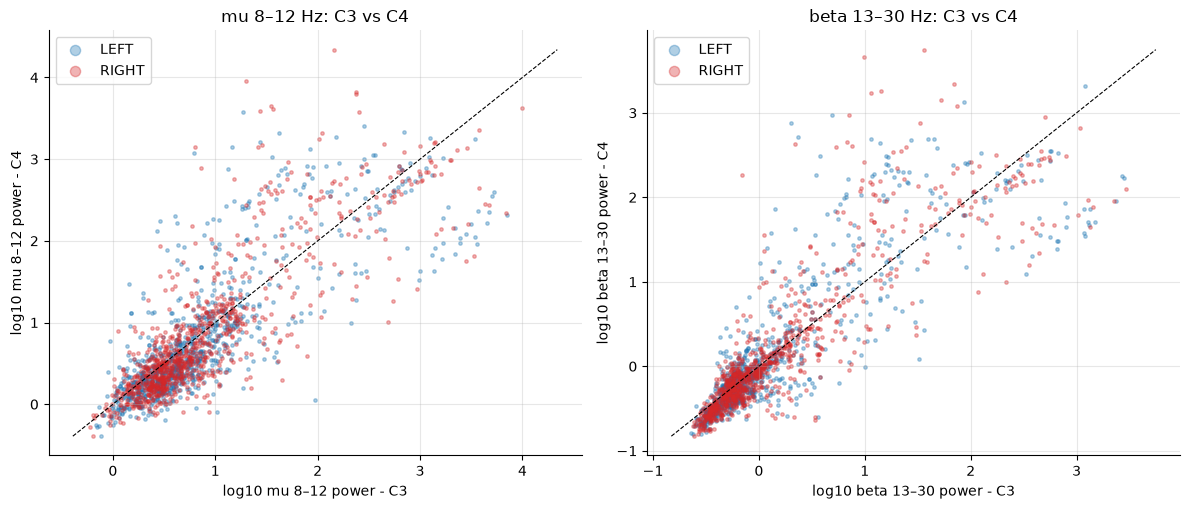

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, (bname, (lo, hi)) in zip(axes, BANDS.items()):
    m_band = (f >= lo) & (f <= hi)
    lp3, lp4 = np.log10(P_nocar[:, C3][:, m_band].mean(-1)), np.log10(P_nocar[:, C4][:, m_band].mean(-1))
    for lab in ("LEFT", "RIGHT"):
        ax.scatter(lp3[y == lab], lp4[y == lab], s=6, alpha=0.35, color=COL[lab], label=lab)
    lim = [min(lp3.min(), lp4.min()), max(lp3.max(), lp4.max())]
    ax.plot(lim, lim, "k--", lw=0.8)
    ax.set_xlabel(f"log10 {bname} power - C3"); ax.set_ylabel(f"log10 {bname} power - C4"); ax.set_title(f"{bname} Hz: C3 vs C4")
    ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

### 6.5 Decision rule

In [14]:
all_d = pd.concat([erd_tab["Cohen d (RIGHT−LEFT)"], bp_tab["d"]]).abs()
pattern_ok = psd_tab.query("version == 'without CAR'")["matches expected"].mean()
print(f"Largest |effect size| in 6.2–6.3: {all_d.max():.3f}   (0.2 = small)")
print(f"PSD differences with the expected sign (C3: RIGHT<LEFT, C4: LEFT<RIGHT), no CAR: {pattern_ok:.0%}")
print(f"PSD differences that are significant (p<0.05): {(psd_tab['t-test p'] < 0.05).sum()} of {len(psd_tab)}")
clear = all_d.max() >= 0.2 and pattern_ok == 1
print("\nDECISION:", "CLEAR LEFT/RIGHT difference -> go to modeling" if clear
      else "NO clear LEFT/RIGHT difference -> check data quality (Section 7) before modeling")

Largest |effect size| in 6.2–6.3: 0.061   (0.2 = small)
PSD differences with the expected sign (C3: RIGHT<LEFT, C4: LEFT<RIGHT), no CAR: 50%
PSD differences that are significant (p<0.05): 0 of 8

DECISION: NO clear LEFT/RIGHT difference -> check data quality (Section 7) before modeling


## 7. Data and label quality
### 7.1 Channel correlation

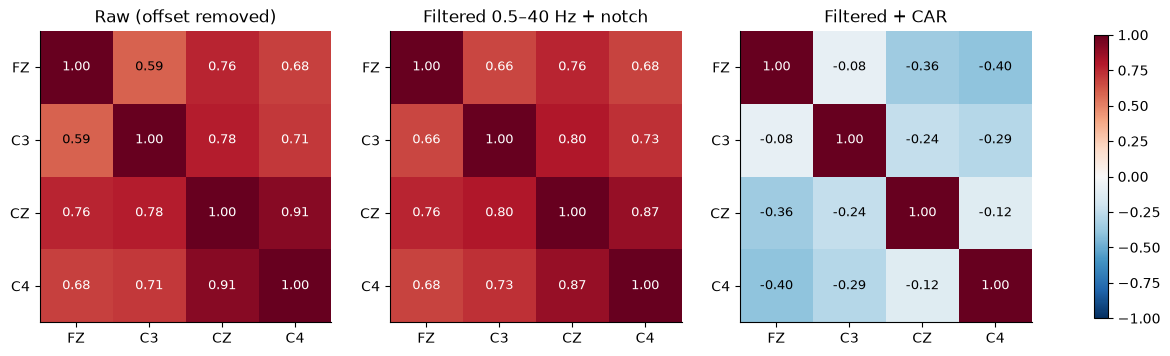

,mean off-diagonal r,C3–C4 r
Raw (offset removed),0.738,0.709
Filtered 0.5–40 Hz + notch,0.753,0.734
Filtered + CAR,-0.248,-0.288


In [15]:
versions = {"Raw (offset removed)": X_raw_k, "Filtered 0.5–40 Hz + notch": X_filt_k, "Filtered + CAR": X_car_k}
mats = {title: np.mean([np.corrcoef(trial) for trial in X[..., s0:s1]], axis=0)
        for title, X in versions.items()}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (title, mat) in zip(axes, mats.items()):
    im = ax.imshow(mat, vmin=-1, vmax=1, cmap="RdBu_r"); ax.grid(False)
    ax.set_xticks(range(len(CH)), CH); ax.set_yticks(range(len(CH)), CH)
    for a in range(len(CH)):
        for b in range(len(CH)):
            ax.text(b, a, f"{mat[a, b]:.2f}", ha="center", va="center", fontsize=9, color="white" if abs(mat[a, b]) > 0.6 else "black")
    ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.8); plt.show()
off = ~np.eye(len(CH), dtype=bool)
pd.DataFrame({"mean off-diagonal r": [mt[off].mean() for mt in mats.values()], "C3–C4 r": [mt[C3, C4] for mt in mats.values()]},
             index=list(mats)).round(3)

### 7.2 Recording sessions

Sessions: 80 over 19.4 days
Trials per session: {9: 41, 18: 5, 27: 6, 36: 10, 45: 2, 54: 3, 63: 6, 72: 4, 81: 1, 90: 2}
Every session is a multiple of 9 trials: True | 9-trial blocks: 240
Gap between trials inside a session: median 0.002 s
File order vs recording order (Spearman rho): -0.19
Sessions with both classes: 80 of 80


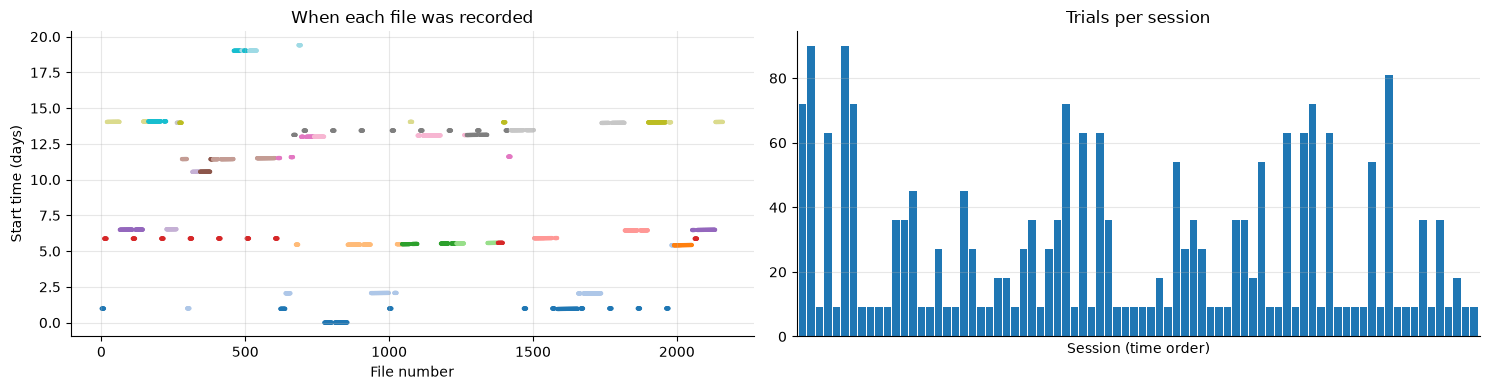

In [16]:
order = trials.sort_values("t_start")
gap = order["t_start"].values[1:] - order["t_end"].values[:-1]
order["session"] = np.cumsum(np.r_[True, gap > cfg["session_gap_seconds"]])
trials["session"] = order["session"]
trials_k["session"] = trials_k["filename"].map(dict(zip(trials["filename"], trials["session"])))
sizes = trials.groupby("session").size()
days = (trials["t_start"].max() - trials["t_start"].min()) / 86400
print(f"Sessions: {trials['session'].nunique()} over {days:.1f} days")
print("Trials per session:", sizes.value_counts().sort_index().to_dict())
print("Every session is a multiple of 9 trials:", bool((sizes % 9 == 0).all()), "| 9-trial blocks:", int((sizes // 9).sum()))
print(f"Gap between trials inside a session: median {np.median(gap[gap <= cfg['session_gap_seconds']]):.3f} s")
print(f"File order vs recording order (Spearman rho): {stats.spearmanr(trials.index, trials['t_start']).statistic:.2f}")
per_s = pd.crosstab(trials["session"], trials["label"])
print("Sessions with both classes:", int(((per_s > 0).sum(axis=1) == 2).sum()), "of", len(per_s))

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].scatter(trials["trial_id"] + 1, (trials["t_start"] - trials["t_start"].min()) / 86400, c=trials["session"], cmap="tab20", s=4)
ax[0].set_xlabel("File number"); ax[0].set_ylabel("Start time (days)"); ax[0].set_title("When each file was recorded")
sizes.plot(kind="bar", ax=ax[1], width=0.9); ax[1].set_xticks([]); ax[1].set_xlabel("Session (time order)"); ax[1].set_title("Trials per session")
plt.tight_layout(); plt.show()

### 7.3 Session vs label effect

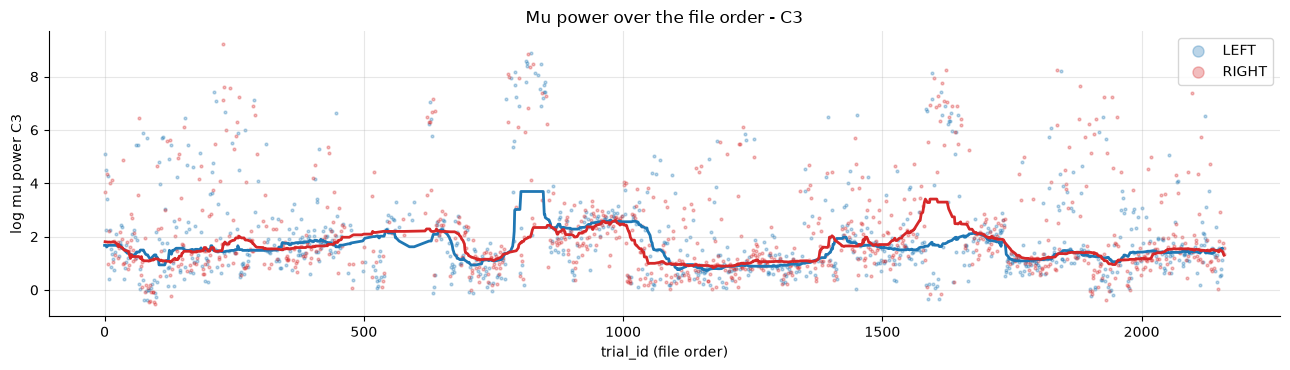

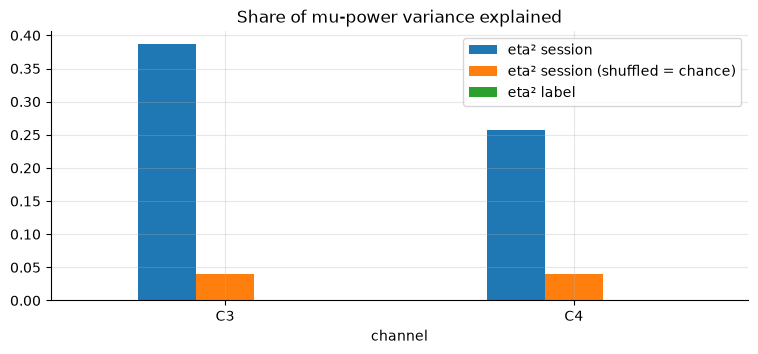

,eta² session,eta² session (shuffled = chance),eta² label
channel,,,
C3,0.3872,0.0398,0.0007
C4,0.2577,0.0394,0.0009


In [17]:
def eta2(values, groups_):
    g = pd.Series(values).groupby(groups_)
    return float(((g.mean() - values.mean()) ** 2 * g.size()).sum() / ((values - values.mean()) ** 2).sum())

ROLL = 50
lp_mu = np.log(P_nocar[..., (f >= MU[0]) & (f <= MU[1])].mean(-1))
tid = trials_k["trial_id"].values
fig, ax = plt.subplots(figsize=(13, 3.8))
for lab in ("LEFT", "RIGHT"):
    s = y == lab
    ax.scatter(tid[s], lp_mu[s, C3], s=4, alpha=0.3, color=COL[lab], label=lab)
    ax.plot(tid[s], pd.Series(lp_mu[s, C3]).rolling(ROLL, center=True, min_periods=ROLL // 2).median(), color=COL[lab], lw=2)
ax.set_xlabel("trial_id (file order)"); ax.set_ylabel("log mu power C3"); ax.set_title("Mu power over the file order - C3")
ax.legend(markerscale=4); plt.tight_layout(); plt.show()

sess = trials_k["session"].values
rows = []
for ch in (C3, C4):
    v = lp_mu[:, ch]
    rows.append({"channel": CH[ch], "eta² session": eta2(v, sess),
                 "eta² session (shuffled = chance)": np.mean([eta2(v, np.random.default_rng(s).permutation(sess)) for s in range(20)]),
                 "eta² label": eta2(v, y)})
eta_tab = pd.DataFrame(rows).set_index("channel")
eta_tab.plot(kind="bar", figsize=(9, 3.5), rot=0, title="Share of mu-power variance explained"); plt.show()
eta_tab.round(4)

### 7.4 Label order

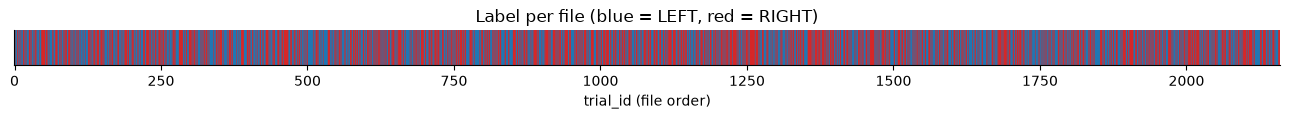

Label runs: 1108 observed vs 1081 expected if random | z = 1.16 | p = 0.245
Longest run of one label: 9 files


In [18]:
fig, ax = plt.subplots(figsize=(13, 1.3))
ax.imshow((y_all == "RIGHT").astype(int)[None, :], aspect="auto", extent=[-0.5, len(y_all) - 0.5, 0, 1],
          cmap=plt.matplotlib.colors.ListedColormap([COL["LEFT"], COL["RIGHT"]])); ax.grid(False)
ax.set_yticks([]); ax.set_xlabel("trial_id (file order)"); ax.set_title("Label per file (blue = LEFT, red = RIGHT)")
plt.tight_layout(); plt.show()

n1, n2 = int((y_all == "LEFT").sum()), int((y_all == "RIGHT").sum()); n = n1 + n2
runs = 1 + int((y_all[1:] != y_all[:-1]).sum())
exp_runs = 1 + 2 * n1 * n2 / n
sd_runs = np.sqrt(2 * n1 * n2 * (2 * n1 * n2 - n) / (n ** 2 * (n - 1)))
z = (runs - exp_runs) / sd_runs
run_len = np.diff(np.flatnonzero(np.r_[True, y_all[1:] != y_all[:-1], True]))
print(f"Label runs: {runs} observed vs {exp_runs:.0f} expected if random | z = {z:.2f} | p = {2 * stats.norm.sf(abs(z)):.3f}")
print(f"Longest run of one label: {run_len.max()} files")

### 7.5 Duplicate files

In [19]:
dup = trials[trials.duplicated("hash", keep=False)]
dup_table = dup.groupby("hash").agg(files=("filename", " = ".join), labels=("label", " / ".join), n=("filename", "size"),
                                    same_label=("label", lambda s: s.nunique() == 1)).reset_index(drop=True)
dup_table.to_csv(f"{OUT}/duplicates.csv", index=False)
n_groups, n_agree = len(dup_table), int(dup_table["same_label"].sum())
print(f"Duplicate groups: {n_groups} (sizes: {dup_table['n'].value_counts().to_dict()}) -> {len(dup)} files involved")
print(f"Groups with the same label: {n_agree} of {n_groups} ({n_agree / n_groups:.0%}) | expected 100% if labels were correct")
print(f"Binomial test vs random labels (50%): p = {stats.binomtest(n_agree, n_groups, 0.5).pvalue:.3f}")

pairs = sorted(sorted(g["trial_id"].values + 1) for _, g in dup.groupby("hash"))
offsets = Counter(int(b - a) for a, b in pairs)
same_ts = all((trials.loc[a - 1, ["t_start", "t_end"]].values == trials.loc[b - 1, ["t_start", "t_end"]].values).all() for a, b in pairs)
print("Distance between the two copies (file numbers) -> number of pairs:", dict(sorted(offsets.items())))
print("All distances are multiples of 9:", all(o % 9 == 0 for o in offsets), "| copies have identical timestamps:", same_ts)
for o in sorted(offsets):
    firsts = [a for a, b in pairs if b - a == o]
    print(f"  block of files {min(firsts)}–{max(firsts)} = files {min(firsts) + o}–{max(firsts) + o}")
dup_table.head(10)

Duplicate groups: 36 (sizes: {2: 36}) -> 72 files involved
Groups with the same label: 12 of 36 (33%) | expected 100% if labels were correct
Binomial test vs random labels (50%): p = 0.065
Distance between the two copies (file numbers) -> number of pairs: {243: 9, 558: 9, 648: 9, 1035: 9}
All distances are multiples of 9: True | copies have identical timestamps: True
  block of files 676–684 = files 919–927
  block of files 1396–1404 = files 1954–1962
  block of files 667–675 = files 1315–1323
  block of files 37–45 = files 1072–1080


,files,labels,n,same_label
0,cellula_MI_data_671.csv = cellula_MI_data_1319.csv,LEFT / RIGHT,2,False
1,cellula_MI_data_42.csv = cellula_MI_data_1077.csv,LEFT / RIGHT,2,False
2,cellula_MI_data_673.csv = cellula_MI_data_1321.csv,LEFT / LEFT,2,True
3,cellula_MI_data_1402.csv = cellula_MI_data_1960.csv,RIGHT / LEFT,2,False
4,cellula_MI_data_1396.csv = cellula_MI_data_1954.csv,LEFT / RIGHT,2,False
5,cellula_MI_data_40.csv = cellula_MI_data_1075.csv,LEFT / RIGHT,2,False
6,cellula_MI_data_675.csv = cellula_MI_data_1323.csv,LEFT / LEFT,2,True
7,cellula_MI_data_668.csv = cellula_MI_data_1316.csv,RIGHT / LEFT,2,False
8,cellula_MI_data_669.csv = cellula_MI_data_1317.csv,LEFT / RIGHT,2,False
9,cellula_MI_data_679.csv = cellula_MI_data_922.csv,LEFT / RIGHT,2,False


### 7.6 Label shift

Agreement with the current pairing (shift 0): 33%
Best shift: 120 -> 72% | shifts reaching 100%: 0


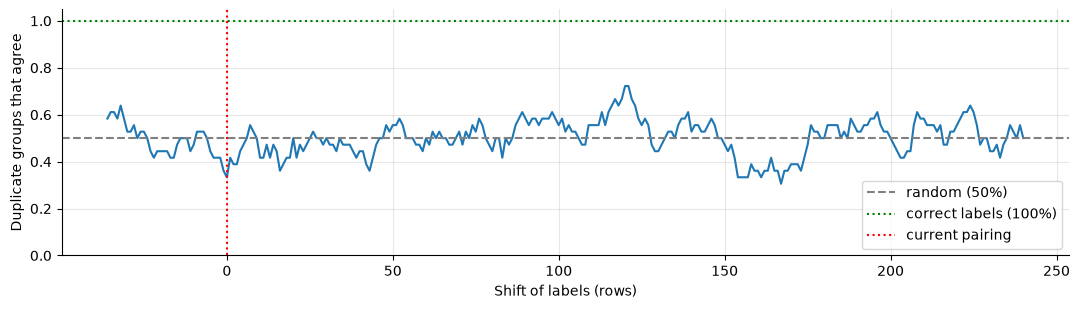

In [20]:
grp_nums = [g["trial_id"].values + 1 for _, g in dup.groupby("hash")]
res = []
for shift in range(-240, 241):
    idx = [g - 1 + shift for g in grp_nums]
    if any((i < 0).any() or (i >= len(all_labels)).any() for i in idx):
        continue
    res.append({"shift": shift, "agree": np.mean([len(set(all_labels[i])) == 1 for i in idx])})
res = pd.DataFrame(res)
best = res.loc[res["agree"].idxmax()]
print(f"Agreement with the current pairing (shift 0): {res.loc[res['shift'] == 0, 'agree'].item():.0%}")
print(f"Best shift: {int(best['shift'])} -> {best['agree']:.0%} | shifts reaching 100%: {(res['agree'] == 1).sum()}")
plt.figure(figsize=(13, 3.2))
plt.plot(res["shift"], res["agree"]); plt.axhline(0.5, color="grey", ls="--", label="random (50%)")
plt.axhline(1.0, color="green", ls=":", label="correct labels (100%)"); plt.axvline(0, color="red", ls=":", label="current pairing")
plt.xlabel("Shift of labels (rows)"); plt.ylabel("Duplicate groups that agree"); plt.legend(); plt.ylim(0, 1.05)
plt.show()

## 8. Preprocessing output

In [21]:
import json

drop = set()
for _, grp in dup.groupby("hash"):
    names = grp.sort_values("trial_id")["filename"].tolist()
    drop.update(names if grp["label"].nunique() > 1 else names[1:])
keep_final = ~trials_k["filename"].isin(drop).values

X_nocar_out = X_ep_nocar[keep_final].astype(np.float32)
X_car_out = X_ep_car[keep_final].astype(np.float32)
y_out = (y[keep_final] == "RIGHT").astype(np.int64)
final = trials_k.loc[keep_final, ["trial_id", "filename", "label", "session"]].reset_index(drop=True)

np.save(f"{OUT}/epochs_noCAR.npy", X_nocar_out)
np.save(f"{OUT}/epochs_CAR.npy", X_car_out)
np.save(f"{OUT}/labels.npy", y_out)
final.to_csv(f"{OUT}/trials_final.csv", index=False)
with open(f"{OUT}/preprocessing_config.json", "w") as fh:
    json.dump({**cfg, "label_map": {"LEFT": 0, "RIGHT": 1}, "shape": list(X_nocar_out.shape),
               "trials_in_files": len(trials), "removed_artifacts": int(bad.sum()),
               "removed_duplicates": int(len(trials_k) - keep_final.sum()), "trials_final": int(len(y_out))}, fh, indent=2)

print(f"Trials: {len(trials)} files -> {len(trials_k)} after artifact rejection -> {len(y_out)} after removing {len(trials_k) - keep_final.sum()} duplicates")
print("Classes [LEFT, RIGHT]:", np.bincount(y_out).tolist(), "| sessions:", final["session"].nunique())
print("Saved:", {f: f"{os.path.getsize(f'{OUT}/{f}') / 1e6:.1f} MB" for f in
                 ["epochs_noCAR.npy", "epochs_CAR.npy", "labels.npy", "trials_final.csv", "preprocessing_config.json"]})
print("Reload check:", np.load(f"{OUT}/epochs_noCAR.npy").shape, np.load(f"{OUT}/labels.npy").shape)

Trials: 2160 files -> 1891 after artifact rejection -> 1831 after removing 60 duplicates
Classes [LEFT, RIGHT]: [916, 915] | sessions: 78
Saved: {'epochs_noCAR.npy': '58.6 MB', 'epochs_CAR.npy': '58.6 MB', 'labels.npy': '0.0 MB', 'trials_final.csv': '0.1 MB', 'preprocessing_config.json': '0.0 MB'}
Reload check: (1831, 4, 2000) (1831,)


## 9. Feature extraction


In [22]:
import bci_features as bf
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score

assert FS == bf.FS and CH == bf.CHANNELS
Xf, yf, groups = X_car_out, y_out, final["session"].values

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, test_idx = next(outer.split(Xf, yf, groups))

splits = final.copy()
splits["split"], splits["fold"] = "dev", -1
splits.loc[test_idx, "split"] = "test"
inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
for k, (_, va) in enumerate(inner.split(Xf[dev_idx], yf[dev_idx], groups[dev_idx])):
    splits.loc[dev_idx[va], "fold"] = k

assert not set(groups[dev_idx]) & set(groups[test_idx])
splits.to_csv(f"{OUT}/cv_splits.csv", index=False)

part = np.where(splits["split"] == "test", "test", "fold " + splits["fold"].astype(str))
display(splits.groupby(part).agg(trials=("label", "size"), sessions=("session", "nunique"),
                                 RIGHT_share=("label", lambda s: round((s == "RIGHT").mean(), 3))))


,trials,sessions,RIGHT_share
fold 0,282,15,0.482
fold 1,300,14,0.510
fold 2,268,14,0.511
fold 3,307,9,0.498
fold 4,330,16,0.515
test,344,10,0.483


### 9.1 Band-power features

In [23]:
bp = bf.BandPower()
F_bp = pd.DataFrame(bp.transform(Xf), columns=bp.get_feature_names_out())
F_bp.to_csv(f"{OUT}/features_bandpower.csv", index=False)

auc_bp = pd.Series({c: roc_auc_score(yf[dev_idx], F_bp.loc[dev_idx, c]) for c in F_bp.columns}, name="AUC (dev)")
print("Band-power features:", F_bp.shape[1])
display(auc_bp.sort_values(key=lambda s: (s - 0.5).abs(), ascending=False).round(3).to_frame().head(8))


Band-power features: 18


,AUC (dev)
Asym_beta_C3-C4,0.475
relBP_mu_CZ,0.520
relBP_mu_C3,0.517
logBP_mu_CZ,0.516
logBP_beta_CZ,0.515
logBP_beta_C4,0.513
logBP_beta_FZ,0.512
relBP_mu_FZ,0.507


Modeling


In [28]:
import time, json, joblib, shutil
import torch
from torch import nn
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)

Xd, yd = Xf[dev_idx], yf[dev_idx]
Xt, yt = Xf[test_idx], yf[test_idx]
fold_dev = splits.loc[dev_idx, "fold"].values
cv_rows, fitters = [], {}

def scores(y_true, p):
    pred = (p >= 0.5).astype(int)
    return {"accuracy": accuracy_score(y_true, pred), "balanced_acc": balanced_accuracy_score(y_true, pred),
            "f1": f1_score(y_true, pred), "auc": roc_auc_score(y_true, p)}

def run_cv(name, fit_predict):
    """fit_predict(X_train, y_train, X_val) -> P(RIGHT). Same 5 folds for every model."""
    cv_rows[:] = [r for r in cv_rows if r["model"] != name]      # safe to re-run a cell
    t0 = time.time()
    for k in range(5):
        tr, va = fold_dev != k, fold_dev == k
        cv_rows.append({"model": name, "fold": k, **scores(yd[va], fit_predict(Xd[tr], yd[tr], Xd[va]))})
    fitters[name] = fit_predict
    res = pd.DataFrame([r for r in cv_rows if r["model"] == name]).drop(columns="model").set_index("fold")
    print(f"{name}: {time.time() - t0:.0f} s | mean AUC {res['auc'].mean():.3f} ± {res['auc'].std():.3f}")
    display(res.round(3))

run_cv("Chance (prior)", lambda Xtr, ytr, Xva: DummyClassifier(strategy="prior").fit(Xtr, ytr).predict_proba(Xva)[:, 1])


Chance (prior): 0 s | mean AUC 0.500 ± 0.000


,accuracy,balanced_acc,f1,auc
fold,,,,
0,0.482,0.5,0.651,0.5
1,0.510,0.5,0.675,0.5
2,0.511,0.5,0.677,0.5
3,0.498,0.5,0.665,0.5
4,0.515,0.5,0.680,0.5


Baseline: CSP + SVM


In [29]:
make_csp_svm = lambda: make_pipeline(bf.FilterBankCSP(bands=((8, 30),), n_pairs=2),   # 4 CSP filters on 8-30 Hz
                                     StandardScaler(), SVC(C=1, probability=True, random_state=SEED))
run_cv("CSP + SVM", lambda Xtr, ytr, Xva: make_csp_svm().fit(Xtr, ytr).predict_proba(Xva)[:, 1])


CSP + SVM: 8 s | mean AUC 0.487 ± 0.030


,accuracy,balanced_acc,f1,auc
fold,,,,
0,0.482,0.500,0.651,0.511
1,0.517,0.507,0.678,0.512
2,0.500,0.492,0.630,0.439
3,0.498,0.500,0.632,0.497
4,0.482,0.480,0.521,0.478


#### Interpreting the baseline


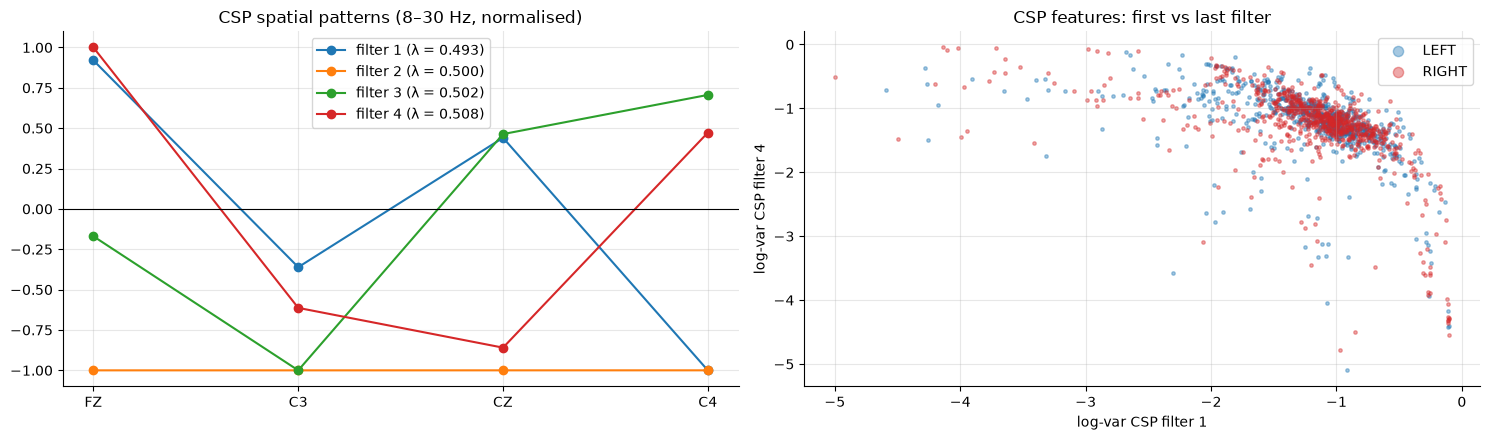

Eigenvalues: [0.493 0.5   0.502 0.508] | distance from 0.5: [0.007 0.    0.002 0.008]
Single-feature AUC (dev): [0.512, 0.485, 0.493, 0.471]


In [30]:
csp_dev = make_csp_svm().fit(Xd, yd)              # dev only, for interpretation
csp = csp_dev[0].csps_[0]
F_csp = csp_dev[0].transform(Xd)                  # log-variance features

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for j, pat in enumerate(csp.patterns_):
    ax[0].plot(CH, pat / np.abs(pat).max(), marker="o", label=f"filter {j + 1} (λ = {csp.eigenvalues_[j]:.3f})")
ax[0].axhline(0, color="black", lw=0.8); ax[0].set_title("CSP spatial patterns (8–30 Hz, normalised)"); ax[0].legend()
for lab, name in [(0, "LEFT"), (1, "RIGHT")]:
    ax[1].scatter(F_csp[yd == lab, 0], F_csp[yd == lab, -1], s=6, alpha=0.4, color=COL[name], label=name)
ax[1].set_xlabel("log-var CSP filter 1"); ax[1].set_ylabel("log-var CSP filter 4")
ax[1].set_title("CSP features: first vs last filter"); ax[1].legend(markerscale=3)
plt.tight_layout(); plt.show()

print("Eigenvalues:", np.round(csp.eigenvalues_, 3), "| distance from 0.5:", np.round(np.abs(csp.eigenvalues_ - 0.5), 3))
print("Single-feature AUC (dev):", [round(roc_auc_score(yd, F_csp[:, j]), 3) for j in range(F_csp.shape[1])])


EEGNet


In [31]:
DECIM, EPOCHS = 2, 40

class EEGNet(nn.Module):
    def __init__(self, n_ch, n_t, F1=8, D=2, F2=16, k=64, drop=0.5):
        super().__init__()
        self.b1 = nn.Sequential(nn.Conv2d(1, F1, (1, k), padding=(0, k // 2), bias=False), nn.BatchNorm2d(F1),
                                nn.Conv2d(F1, F1 * D, (n_ch, 1), groups=F1, bias=False), nn.BatchNorm2d(F1 * D),
                                nn.ELU(), nn.AvgPool2d((1, 4)), nn.Dropout(drop))
        self.b2 = nn.Sequential(nn.Conv2d(F1 * D, F1 * D, (1, 16), padding=(0, 8), groups=F1 * D, bias=False),
                                nn.Conv2d(F1 * D, F2, 1, bias=False), nn.BatchNorm2d(F2),
                                nn.ELU(), nn.AvgPool2d((1, 8)), nn.Dropout(drop))
        with torch.no_grad():
            n_flat = self.b2(self.b1(torch.zeros(1, 1, n_ch, n_t))).numel()
        self.fc = nn.Linear(n_flat, 2)
    def forward(self, x):
        return self.fc(self.b2(self.b1(x)).flatten(1))

def to_tensor(sc, X):
    return torch.from_numpy(sc.transform(X[..., ::DECIM])[:, None])

def train_net(Net, Xtr, ytr):
    torch.manual_seed(SEED)
    sc = bf.ChannelStandardizer().fit(Xtr[..., ::DECIM])           # training trials only
    X_, y_ = to_tensor(sc, Xtr), torch.from_numpy(ytr).long()
    net = Net(X_.shape[2], X_.shape[3])
    opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-3)
    g = torch.Generator().manual_seed(SEED)
    for _ in range(EPOCHS):
        net.train()
        for b in torch.randperm(len(y_), generator=g).split(64):
            opt.zero_grad()
            nn.functional.cross_entropy(net(X_[b]), y_[b]).backward()
            opt.step()
    return net.eval(), sc

def predict_net(net, sc, X):
    with torch.no_grad():
        return torch.softmax(net(to_tensor(sc, X)), 1)[:, 1].numpy()

print("EEGNet parameters:", sum(p.numel() for p in EEGNet(len(CH), Xd.shape[-1] // DECIM).parameters()))
run_cv("EEGNet", lambda Xtr, ytr, Xva: predict_net(*train_net(EEGNet, Xtr, ytr), Xva))


EEGNet parameters: 2162
EEGNet: 336 s | mean AUC 0.491 ± 0.024


,accuracy,balanced_acc,f1,auc
fold,,,,
0,0.496,0.497,0.489,0.492
1,0.483,0.481,0.551,0.476
2,0.481,0.481,0.502,0.501
3,0.485,0.486,0.524,0.461
4,0.485,0.486,0.469,0.523


### 10.3 CNN-LSTM


In [32]:
class CNNLSTM(nn.Module):
    def __init__(self, n_ch, n_t, hidden=32, drop=0.5):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(n_ch, 16, 7, padding=3), nn.BatchNorm1d(16), nn.ELU(), nn.MaxPool1d(4), nn.Dropout(drop),
            nn.Conv1d(16, 32, 7, padding=3), nn.BatchNorm1d(32), nn.ELU(), nn.MaxPool1d(4), nn.Dropout(drop))
        self.lstm = nn.LSTM(32, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 2)
    def forward(self, x):                                  # (batch, 1, channels, time)
        z = self.cnn(x.squeeze(1)).transpose(1, 2)         # (batch, time steps, features)
        _, (h, _) = self.lstm(z)
        return self.fc(h[-1])

NETS = {"EEGNet": EEGNet, "CNN-LSTM": CNNLSTM}
print("CNN-LSTM parameters:", sum(p.numel() for p in CNNLSTM(len(CH), Xd.shape[-1] // DECIM).parameters()))
run_cv("CNN-LSTM", lambda Xtr, ytr, Xva: predict_net(*train_net(CNNLSTM, Xtr, ytr), Xva))


CNN-LSTM parameters: 12690
CNN-LSTM: 196 s | mean AUC 0.470 ± 0.031


,accuracy,balanced_acc,f1,auc
fold,,,,
0,0.479,0.479,0.469,0.451
1,0.473,0.472,0.521,0.463
2,0.481,0.477,0.562,0.433
3,0.482,0.482,0.485,0.497
4,0.479,0.491,0.140,0.506


Model comparison (CV on dev)

accuracy        balanced_acc            f1           auc       
                   mean    std         mean    std   mean    std   mean    std
model                                                                         
Chance (prior)    0.503  0.013        0.500  0.000  0.670  0.012  0.500  0.000
CSP + SVM         0.496  0.014        0.496  0.010  0.622  0.060  0.487  0.030
EEGNet            0.486  0.006        0.486  0.007  0.507  0.032  0.491  0.024
CNN-LSTM          0.479  0.003        0.480  0.007  0.435  0.169  0.470  0.031

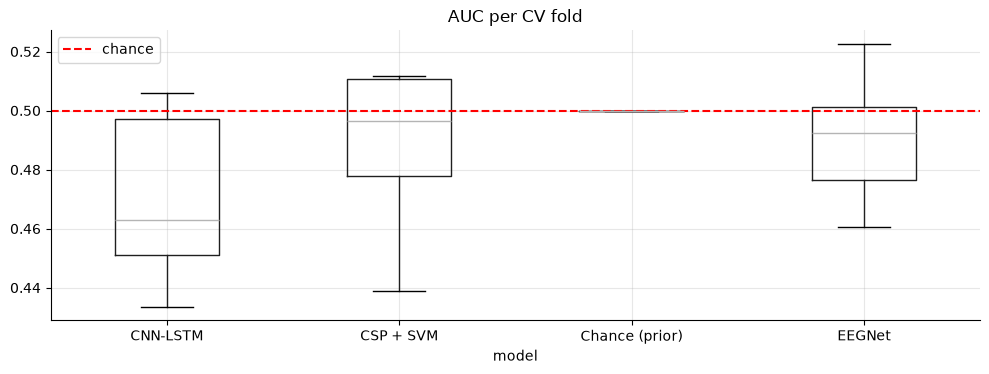

In [33]:
cv = pd.DataFrame(cv_rows)
cv.to_csv(f"{OUT}/cv_results.csv", index=False)
order = list(fitters)
cv_sum = cv.groupby("model")[["accuracy", "balanced_acc", "f1", "auc"]].agg(["mean", "std"]).round(3).loc[order]
display(cv_sum)

ax = cv.boxplot(column="auc", by="model", figsize=(10, 4), positions=None)
ax.axhline(0.5, color="red", ls="--", label="chance"); ax.set_title("AUC per CV fold"); ax.legend()
plt.suptitle(""); plt.tight_layout(); plt.show()


who fits the data? fold scores vs chance 


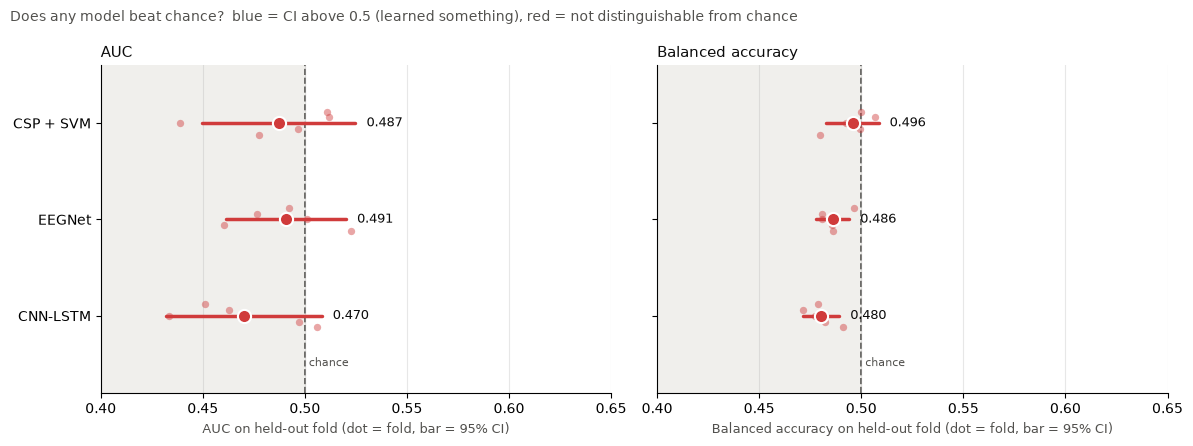

mean              p_vs_chance              beats_chance  \
metric          auc balanced_acc         auc balanced_acc          auc   
model                                                                    
CSP + SVM  0.487113     0.495706    0.802173     0.798838        False   
EEGNet     0.490662     0.485918    0.785694      0.99575        False   
CNN-LSTM   0.470097     0.480199    0.952543       0.9982        False   

                        
metric    balanced_acc  
model                   
CSP + SVM        False  
EEGNet           False  
CNN-LSTM         False

In [ ]:
metrics = {"auc": "AUC", "balanced_acc": "Balanced accuracy"}
models = [m for m in order if m != "Chance (prior)"]
INK, MUTED, BLUE, RED = "#0b0b0b", "#52514e", "#2a78d6", "#d03b3b"

rows = []
for m in models:
    for k in metrics:
        v = cv.loc[cv["model"] == m, k].to_numpy()
        half = stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
        p = stats.ttest_1samp(v, 0.5, alternative="greater").pvalue
        rows.append({"model": m, "metric": k, "mean": v.mean(), "ci_low": v.mean() - half,
                     "ci_high": v.mean() + half, "p_vs_chance": p, "beats_chance": (v.mean() - half) > 0.5})
verdict = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 0.9 * len(models) + 1.8), sharey=True)
for ax, (k, name) in zip(axes, metrics.items()):
    ax.axvspan(0, 0.5, color="#f0efec", zorder=0)
    ax.axvline(0.5, color=MUTED, ls="--", lw=1.2, zorder=1)
    for i, m in enumerate(models):
        v = cv.loc[cv["model"] == m, k].to_numpy()
        r = verdict[(verdict.model == m) & (verdict.metric == k)].iloc[0]
        c = BLUE if r.beats_chance else RED
        ax.scatter(v, np.full(len(v), i) + np.linspace(-0.12, 0.12, len(v)), s=28, color=c, alpha=0.45, lw=0, zorder=2)
        ax.plot([r.ci_low, r.ci_high], [i, i], color=c, lw=2.5, solid_capstyle="round", zorder=3)
        ax.scatter(r["mean"], i, s=90, color=c, edgecolor="white", lw=1.5, zorder=4)
        ax.annotate(f"{r['mean']:.3f}", (r.ci_high, i), xytext=(8, 0), textcoords="offset points",
                    va="center", fontsize=9, color=INK)
    lo = min(0.4, cv.loc[cv.model.isin(models), k].min() - 0.02)
    hi = max(0.65, cv.loc[cv.model.isin(models), k].max() + 0.04)
    ax.set_xlim(lo, hi); ax.set_title(name, loc="left", fontsize=11, color=INK)
    ax.set_xlabel(f"{name} on held-out fold (dot = fold, bar = 95% CI)", color=MUTED, fontsize=9)
    ax.text(0.5, len(models) - 0.45, " chance", color=MUTED, fontsize=8, va="bottom")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(models)), models); axes[0].set_ylim(-0.6, len(models) - 0.2); axes[0].invert_yaxis()
fig.suptitle("Does any model beat chance?  blue = CI above 0.5 (learned something), red = not distinguishable from chance",
             x=0.01, ha="left", fontsize=10, color=MUTED)
plt.tight_layout(); plt.show()

display(verdict.pivot(index="model", columns="metric", values=["mean", "p_vs_chance", "beats_chance"]).loc[models].round(3))
